<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  149 non-null    float64
 1   sepal_width   149 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   148 non-null    float64
 4   target        150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB
Accuracy og kNN with k=7: 93.18%


c:\Users\vikto\miniconda3\envs\aau-ai\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


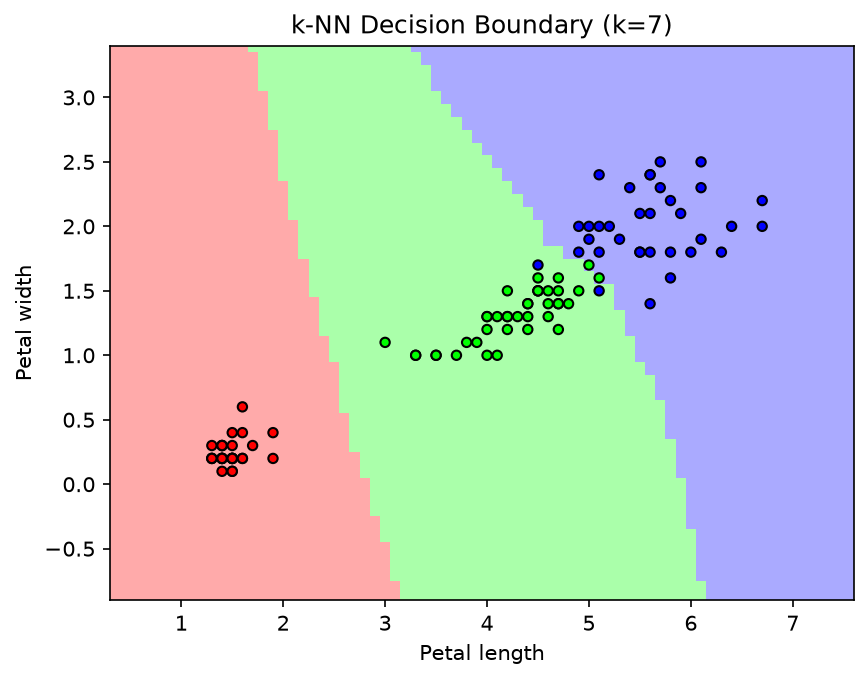

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
import numpy as np
from matplotlib.colors import ListedColormap

# Read data
df = pd.read_csv("iris.csv")

iris = df.sample(frac=1, random_state=42).reset_index(drop=True)

# Head and tail
df.head(5) 
df.tail(5)

# Info
df.info()

# Descriptive statistics
df.describe()

# Handling Missing Values
df = df.dropna()

df_fillna = df.fillna(0) # Filling missing values with 0

# Load the Iris dataset
X = df.iloc[:, 2]
y = df.iloc[:, -1]

# Spilt the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Create a kNN classifier with a specified value of k (e.g., k=3)
k = 7
knn_classifier = KNeighborsClassifier(n_neighbors=k)

# Fit the classifier to the training data

# Convert the single feature Series to 2D DataFrames
X_train = X_train.to_frame()
X_test = X_test.to_frame()

# Fit the classifier
knn_classifier.fit(X_train, y_train)

# Make predictions on the test set
y_pred = knn_classifier.predict(X_test)

#Calculate the accuracy of the model
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy og kNN with k={k}: {accuracy * 100:.2f}%")

# Visualisation #

# Use two features for 2D visualization
X = df.iloc[:, 2:4]  # petal_length and petal_width
y = df.iloc[:, -1]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

knn_classifier = KNeighborsClassifier(n_neighbors=k)
knn_classifier.fit(X_train, y_train)

# Create a mesh grid to visualize the decision boundary
h = 0.1  # Step size in the mesh
x_min, x_max = X_train.iloc[:, 0].min() - 1, X_train.iloc[:, 0].max() + 1
y_min, y_max = X_train.iloc[:, 1].min() - 1, X_train.iloc[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

# Predict the class for each point in the mesh
grid_points = np.c_[xx.ravel(), yy.ravel()]
Z = knn_classifier.predict(grid_points).reshape(xx.shape)

# Create a color map for the decision boundaries
cmap_light = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF'])
cmap_bold = ListedColormap(['#FF0000', '#00FF00', '#0000FF'])

# Plot the decision boundaries
import matplotlib.pyplot as plt
plt.figure(dpi=150)
plt.pcolormesh(xx, yy, Z, cmap=cmap_light)
plt.scatter(X_train.iloc[:, 0], X_train.iloc[:, 1], c=y_train, cmap=cmap_bold, edgecolor='k', s=20)
#plt.scatter(X_test.iloc[:, 0], X_test.iloc[:, 1], c=y_test, cmap=cmap_bold, edgecolor='k', s=20)
plt.xlim(xx.min(), xx.max())
plt.ylim(yy.min(), yy.max())
plt.title(f"k-NN Decision Boundary (k={k})")
plt.xlabel("Petal length")
plt.ylabel("Petal width")
plt.show()